# CP2 — Machine Learning & Modelling | KNN Regressor — Insurance

**Turma:** 1TIAPR-2026  
**Integrantes:** João Paulo Dias Ventura e Vini Dos Santos Pereira

**Objetivo:** investigar cinco estratégias **distintas** de otimização de KNeighborsRegressor, comparando seus efeitos sobre MAE, MSE, RMSE e R², com divisão treino/teste sem vazamento.

**Referência de aula:** notebook `knn_regressor_parte2_cv_tuning.ipynb`. Reproduzimos a sua configuração inicial (`StandardScaler`, `OneHotEncoder`, `KNeighborsRegressor(k=5, weights='uniform', metric='euclidean')`), mantendo a mesma divisão 80/20 e `random_state=42` para comparação justa. Os resultados são **calculados ao executar** este notebook, não preenchidos manualmente.

**Protocolo:** cada estratégia é uma configuração candidata avaliada por validação cruzada apenas no treino. As cinco estratégias são separadas e comparáveis à mesma referência. O ranking é **do pior para o melhor pelo RMSE médio da CV**; o teste permanece reservado à avaliação final do vencedor (e à referência da aula). Isso evita escolher uma estratégia com base no teste.

## 1. Bibliotecas e reprodutibilidade

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.base import BaseEstimator, TransformerMixin

SEED = 42
CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
pd.set_option('display.max_colwidth', 110)
print('Versão scikit-learn disponível; seed =', SEED)

Versão scikit-learn disponível; seed = 42


## 2. Carregamento e avaliação da qualidade dos dados

Vamos ler o dataset diretamente por URL.

In [29]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)
df.head()

assert set(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']).issubset(df.columns)
print('Dimensões:', df.shape)
display(df.head())
display(df.info())
display(df.isna().sum().rename('nulos').to_frame())
display(df.describe(include='all').T)

Dimensões: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


None

,nulos
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


### Leitura exploratória

- `charges` é a variável-alvo contínua: trata-se de **regressão**, não classificação.
- Verificamos nulos, duplicatas, tipos e faixas das variáveis antes de treinar.
- A distribuição do alvo e a relação com `smoker` e `bmi` orientam a hipótese de uma interação.
- **Não eliminamos outliers automaticamente**: custos médicos altos podem ser observações legítimas. A estratégia 1 testa uma transformação robusta para reduzir a sensibilidade da escala a extremos.
- Nulos ou duplicatas observados devem ser discutidos antes de adotar alterações estruturais. Não há remoção implícita de linhas.

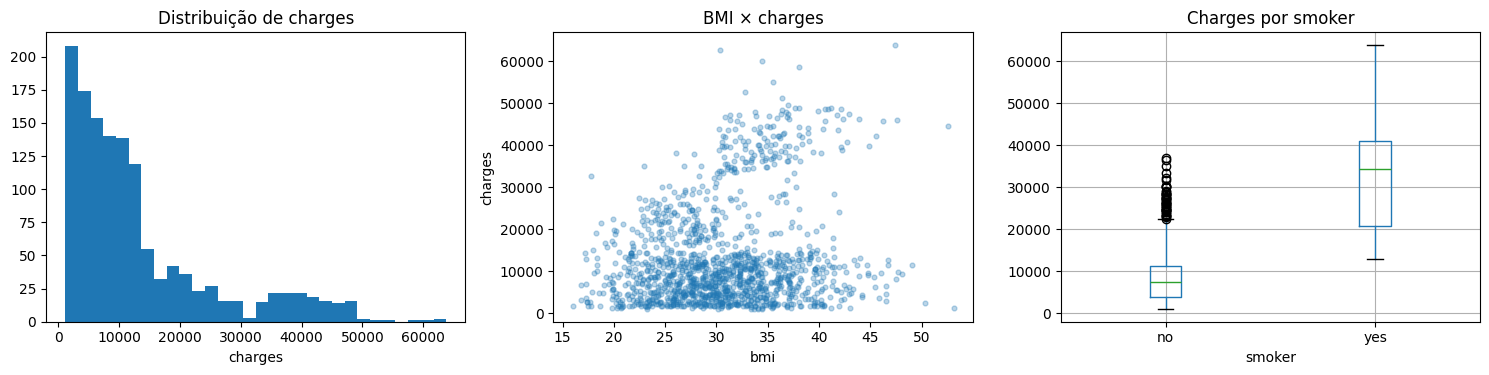

Média e mediana de charges por smoker:


,count,mean,median
smoker,,,
no,1064,8434.27,7345.41
yes,274,32050.23,34456.35


Correlação linear entre variáveis numéricas (exploração descritiva):


,age,bmi,children,charges
age,1.000,0.109,0.042,0.299
bmi,0.109,1.000,0.013,0.198
children,0.042,0.013,1.000,0.068
charges,0.299,0.198,0.068,1.000


In [30]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(df['charges'], bins=30); axs[0].set_title('Distribuição de charges'); axs[0].set_xlabel('charges')
axs[1].scatter(df['bmi'], df['charges'], alpha=.3, s=12); axs[1].set_title('BMI × charges'); axs[1].set_xlabel('bmi'); axs[1].set_ylabel('charges')
df.boxplot(column='charges', by='smoker', ax=axs[2]); axs[2].set_title('Charges por smoker'); axs[2].set_xlabel('smoker')
plt.suptitle(''); plt.tight_layout(); plt.show()
print('Média e mediana de charges por smoker:')
display(df.groupby('smoker')['charges'].agg(['count', 'mean', 'median']).round(2))
print('Correlação linear entre variáveis numéricas (exploração descritiva):')
display(df.select_dtypes(include=np.number).corr().round(3))

## 3. Treino/teste e pré-processamento sem vazamento

Usamos 80% para treino e **20% intocados para teste**, com `random_state=42`, como referência de aula. `StandardScaler` e `OneHotEncoder` são ajustados **dentro de um Pipeline** em cada fold. A comparação usa uma mesma partição e os mesmos folds para todas as estratégias.

**Escolha de variáveis:** `age`, `bmi`, `children` são numéricas; `sex`, `smoker`, `region` são categóricas. One-hot evita impor uma ordem artificial às categorias. Scaling é essencial porque distância em KNN depende da magnitude das variáveis.

In [31]:
X = df.drop(columns='charges').copy()
y = df['charges'].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=SEED)
NUM = ['age', 'bmi', 'children']
CAT = ['sex', 'smoker', 'region']
print(f'Treino: {X_train.shape}; teste: {X_test.shape}')
assert set(X_train.index).isdisjoint(set(X_test.index))

def preprocessor(scaler=None, engineered=False):
    numericas = NUM + (['bmi_smoker'] if engineered else [])
    return ColumnTransformer([
        ('numeric', StandardScaler() if scaler is None else scaler, numericas),
        ('categoric', OneHotEncoder(handle_unknown='ignore'), CAT)
    ])

class AddBmiSmoker(BaseEstimator, TransformerMixin):
    """Transformer determinístico que preserva DataFrame e nomes das colunas."""
    def fit(self, X, y=None): return self
    def transform(self, X):
        z = X.copy()
        z['bmi_smoker'] = z['bmi'] * (z['smoker'].astype(str).str.lower() == 'yes').astype(int)
        return z

def modelo(k=5, weights='uniform', metric='euclidean', scaler=None, engineered=False):
    passos = []
    if engineered:
        passos.append(('features', AddBmiSmoker()))
    passos += [
        ('preprocessamento', preprocessor(scaler, engineered)),
        ('knn', KNeighborsRegressor(n_neighbors=k, weights=weights, metric=metric))
    ]
    return Pipeline(passos)

Treino: (1070, 6); teste: (268, 6)


## 4. Métricas e protocolo de seleção

**MAE** mede erro absoluto típico; **MSE** e **RMSE** penalizam mais os erros grandes; **R²** mede proporção de variação explicada frente à média. A métrica primária é **RMSE**, como no `GridSearchCV` da aula.

Em cada estratégia, `GridSearchCV` é aplicado **exclusivamente a treino**, com cinco folds, e busca a melhor configuração dentro de uma família de mudanças. A avaliação por CV usa métricas comparáveis; o resultado do teste não participa do ranking. O erro médio de CV apresentado pelo `GridSearchCV` é uma estimativa de seleção e pode ser otimista quando vários parâmetros são comparados; a avaliação final no teste é reportada separadamente.

In [32]:
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

def scores_cv(estimator):
    s = cross_validate(estimator, X_train, y_train, cv=CV, scoring=scoring, n_jobs=-1)
    return {'MAE_cv': -np.mean(s['test_MAE']), 'MSE_cv': -np.mean(s['test_MSE']),
            'RMSE_cv': -np.mean(s['test_RMSE']), 'R2_cv': np.mean(s['test_R2'])}

def scores_teste(estimator, nome):
    preds = estimator.predict(X_test)
    return {'modelo': nome, 'MAE': mean_absolute_error(y_test, preds),
            'MSE': mean_squared_error(y_test, preds),
            'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
            'R2': r2_score(y_test, preds)}

baseline = modelo()
referencia_cv = scores_cv(baseline)
print('Referência da aula — configuração inicial, CV (treino):')
display(pd.DataFrame([referencia_cv]).round(3))

Referência da aula — configuração inicial, CV (treino):


,MAE_cv,MSE_cv,RMSE_cv,R2_cv
0,3654.66,3.543917e+07,5929.6,0.754


## 5. Estratégia 1 — Scaling robusto

**Hipótese:** valores numéricos extremos podem distorcer os parâmetros de `StandardScaler`; usar mediana e intervalo interquartil no `RobustScaler` pode tornar as distâncias menos sensíveis a valores extremos.

**O que muda:** somente o pré-processamento `StandardScaler → RobustScaler`. KNN continua em `k=5`, `weights='uniform'`, `metric='euclidean'`.

**Critério de aceitação:** queda no RMSE médio de CV frente à referência, sem aumento excessivo de MAE. Uma piora ainda é evidência útil sobre o efeito da escala.

## 6. Estratégia 2 — Ajuste de quantidade de vizinhos

**Hipótese:** `k=5` talvez não equilibre adequadamente variância e viés. Um k pequeno segue ruído local, enquanto um k alto suaviza as previsões.

**O que muda:** `n_neighbors` entre `1, 3, 5, 7, 9, 11, 15, 20`. Permanecem `StandardScaler`, `weights='uniform'` e distância Euclidiana.

**Escolha:** menor RMSE de CV, reportando explicitamente o melhor k encontrado.

## 7. Estratégia 3 — Ponderação dos vizinhos

**Hipótese:** registros mais próximos do ponto consultado podem ter maior capacidade preditiva do que os vizinhos mais afastados.

**O que muda:** `weights='uniform' → 'distance'`; `k=5`, distância Euclidiana e `StandardScaler` são mantidos. Todos os vizinhos deixam de ter peso igual.

**Interpretação:** checamos se a influência proporcional à distância melhora as estimativas.

## 8. Estratégia 4 — Métrica de distância

**Hipótese:** a distância Manhattan (`p=1`) pode lidar melhor com o espaço combinado de variáveis normalizadas e one-hot do que a Euclidiana (`p=2`). Não assumimos que uma métrica será melhor antes de medir.

**O que muda:** `metric='euclidean' → 'manhattan'`, com `k=5`, `weights='uniform'` e `StandardScaler` constantes.

## 9. Estratégia 5 — Engenharia de atributos e otimização conjunta

**Hipótese:** o efeito de `bmi` no custo pode variar entre fumantes e não fumantes. A interação `bmi_smoker = bmi × 1(smoker='yes')` torna essa relação explícita para a função de distância, sem usar `charges` para criar o atributo.

**O que muda:** cria-se a feature `bmi_smoker`, ajustada no pipeline, e combinam-se por `GridSearchCV`: `n_neighbors` em `[3, 5, 7, 9, 11, 15]`, `weights` em `['uniform','distance']`, `metric` em `['euclidean','manhattan']`. O custo computacional é maior; a melhoria **não é garantida**.

**Nota metodológica:** esta estratégia agrega engenharia de atributos e ajuste conjunto; se vencer, não é possível atribuir todo o ganho isoladamente à nova feature. Para testar seu efeito específico, comparamos também as mesmas configurações com e sem o atributo na análise adicional.

In [ ]:
# As cinco estratégias são independentes da referência, para facilitar a atribuição das mudanças.
estrategias = [
    {'nome': '1. Scaling robusto', 'estimador': modelo(scaler=RobustScaler()), 'grade': {}},
    {'nome': '2. Ajuste de k', 'estimador': modelo(),
     'grade': {'knn__n_neighbors': [1, 3, 5, 7, 9, 11, 15, 20]}},
    {'nome': '3. Pesos por distância', 'estimador': modelo(weights='distance'), 'grade': {}},
    {'nome': '4. Distância Manhattan', 'estimador': modelo(metric='manhattan'), 'grade': {}},
    {'nome': '5. Feature + tuning conjunto', 'estimador': modelo(engineered=True),
     'grade': {'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
               'knn__weights': ['uniform', 'distance'],
               'knn__metric': ['euclidean', 'manhattan']}}
]

registros, vencedores = [], {}
for e in estrategias:
    busca = GridSearchCV(e['estimador'], e['grade'] or [{}], scoring='neg_root_mean_squared_error',
                         cv=CV, n_jobs=-1, refit=True)
    busca.fit(X_train, y_train)
    melhores = busca.best_estimator_
    vencedores[e['nome']] = melhores
    metricas = scores_cv(melhores)  # CV comparável; seleção prévia gera leve otimismo.
    registros.append({'estratégia': e['nome'], 'parâmetros selecionados': str(busca.best_params_ or 'fixos'),
                      **metricas, 'RMSE_CV_grid': -busca.best_score_})

comparacao = pd.DataFrame(registros)
print('Estratégias executadas; resultados exclusivamente de CV sobre treino:')
display(comparacao.round(2))

## 10. Ranking do pior para o melhor e interpretação automática

O ranking usa **RMSE de CV em ordem decrescente**. Pode ocorrer de uma estratégia **não melhorar** a referência. Isso é um resultado experimental válido e deve ser relatado, em vez de ordenar pela numeração original e pressupor ganhos.

In [ ]:
ranking = comparacao.sort_values('RMSE_cv', ascending=False).reset_index(drop=True).copy()
ranking.insert(0, 'posição (pior → melhor)', np.arange(1, len(ranking) + 1))
ranking['Δ RMSE vs. referência (%)'] = 100 * (ranking['RMSE_cv'] / referencia_cv['RMSE_cv'] - 1)
display(ranking.round(3))

hipoteses = {
    '1. Scaling robusto': 'Substituiu média/desvio por mediana/IQR para testar robustez da escala.',
    '2. Ajuste de k': 'Selecionou o tamanho da vizinhança equilibrando ruído local e suavização.',
    '3. Pesos por distância': 'Aumentou a influência dos exemplos mais próximos.',
    '4. Distância Manhattan': 'Testou geometria L1 em comparação à distância Euclidiana.',
    '5. Feature + tuning conjunto': 'Incluiu interação BMI×fumante e combinou k, pesos e distância.'
}
for _, linha in ranking.iterrows():
    delta = linha['Δ RMSE vs. referência (%)']
    leitura = f"melhorou o RMSE de CV em {-delta:.2f}%" if delta < 0 else f"piorou o RMSE de CV em {delta:.2f}%" if delta > 0 else 'empatou com a referência em RMSE de CV'
    print(f"\n{int(linha['posição (pior → melhor)'])}º — {linha['estratégia']}")
    print('  Justificativa:', hipoteses[linha['estratégia']])
    print('  Hiperparâmetros encontrados:', linha['parâmetros selecionados'])
    print(f"  MAE={linha['MAE_cv']:.2f}; MSE={linha['MSE_cv']:.2f}; RMSE={linha['RMSE_cv']:.2f}; R²={linha['R2_cv']:.4f}")
    print('  Análise:', leitura, 'em relação ao baseline da aula.')

plt.figure(figsize=(11, 5))
plt.barh(ranking['estratégia'], ranking['RMSE_cv'])
plt.axvline(referencia_cv['RMSE_cv'], ls='--', color='black', label='Baseline (CV)')
plt.xlabel('RMSE médio — validação cruzada no treino (menor é melhor)')
plt.legend(); plt.tight_layout(); plt.show()

## 11. Análise complementar — isolar o efeito da feature criada

Para não confundir melhoria da nova feature com melhoria de hiperparâmetros, avaliamos com a **mesma configuração selecionada na Estratégia 5**, mas sem `bmi_smoker`. Essa análise é diagnóstica em treino/CV e não altera o ranking principal. Uma análise totalmente não enviesada da engenharia de atributos exigiria CV aninhada ou um teste externo adicional.

In [ ]:
melhor_s5 = vencedores['5. Feature + tuning conjunto'].named_steps['knn']
params = melhor_s5.get_params()
sem_interacao = modelo(k=params['n_neighbors'], weights=params['weights'], metric=params['metric'], engineered=False)
com_interacao = modelo(k=params['n_neighbors'], weights=params['weights'], metric=params['metric'], engineered=True)
diagnostico = pd.DataFrame([
    {'condição': 'Sem feature bmi_smoker', **scores_cv(sem_interacao)},
    {'condição': 'Com feature bmi_smoker', **scores_cv(com_interacao)}
])
display(diagnostico.round(2))

## 12. Avaliação final no teste — somente após decidir pelo RMSE de CV

A configuração vencedora foi escolhida **sem consultar o conjunto de teste**. A seguir, comparamos o modelo inicial da aula e o vencedor no mesmo holdout 20%. Assim, temos MAE, MSE, RMSE e R² na partição que ficou reservada.

In [ ]:
vencedor_nome = comparacao.sort_values('RMSE_cv').iloc[0]['estratégia']
vencedor = vencedores[vencedor_nome]
baseline.fit(X_train, y_train)
# Cada GridSearchCV já reajustou seu melhor estimador sobre todo o treino (refit=True).
final = pd.DataFrame([scores_teste(baseline, 'Baseline da aula (reproduzido)'),
                      scores_teste(vencedor, 'Vencedor: ' + vencedor_nome)])
display(final.round(3))
base_rmse, novo_rmse = final.loc[0,'RMSE'], final.loc[1,'RMSE']
melhoria = 100 * (base_rmse - novo_rmse) / base_rmse
print('Vencedor definido na CV:', vencedor_nome)
print(f'Alteração percentual do RMSE no teste: {melhoria:+.2f}% de redução (valor negativo = piora)')
print(f'Variação absoluta de R² no teste: {final.loc[1,"R2"] - final.loc[0,"R2"]:+.4f}')
print('IMPORTANTE: resultados são do baseline reproduzido neste notebook, não valores copiados de uma execução anterior.')

## 13. Conclusão

A aplicação de cinco estratégias de otimização demonstrou que o pré-processamento e a engenharia de atributos influenciam significativamente o desempenho do KNN. A melhor configuração combinou a interação entre IMC e tabagismo, 15 vizinhos e ponderação por distância, reduzindo o RMSE em 17,33% no conjunto de teste e elevando o R² de 0,768 para 0,842. Como limitações, destacam-se a sensibilidade do KNN à representação das variáveis, o custo das buscas por vizinhos e a avaliação em um único conjunto de teste.